# CS145: Project 1 | A Scent for All Seasons (Pt. 1) — Seasonal Trends Indicated by Amazon Users' Reviews of Scented Beauty and Personal Care Products

**Engine:** DuckDB SQL with Python (no personal google account for BigQuery).

**Data:** [McAuley Lab Amazon Reviews](https://amazon-reviews-2023.github.io/index.html) 2023, starting with `All Beauty` reviews and metadata, and expanding to `Beauty and Personal Care` reviews and metadata.


## Table of Contents

1. [Project Overview](#section-1)
2. [Dataset Analysis](#section-2)
3. [Get Your Feet Wet](#section-3)
4. [Exploring Central Questions](#section-4)
5. [AI Takeaways](#section-5)
6. [Wrap-Up](#section-6)

---

<a name="section-1"></a>

# Section 1: Project Overview

---
Research Questions:

1. Seasonality: Which calendar months have disproportionately high scented-product review activity, controlling for yearly review volume and length of month in days?

2. Seasonal Favorites: Which scented product subcategories gain relatively more attention during different seasons (months Dec-Jan, for example)?

3. Seasonal Verification: Does the proportion of scented-product reviews marked as "verified purchases" vary by season and / or by product subcategory?



Shoppers associate fragrances with the seasons. We therefore want to ask, based on *Amazon* review data in the [scented *Beauty and Personal Care* product category](https://amazon-reviews-2023.github.io/index.html) (Hu et al. 2024), which types of scented products seem to vary by season in the volume of user reviews they receive, and which types of scented beauty products are reviewed all year long. These data can indicate consumer preferences to stockists of scented beauty products, such as body sprays and perfumes, and therefore inform inventory planning.

However: reviews are not sales, reviews can lag purchases by months, and the  seasons that we assume correspond to months in the Northern hemisphere may not correspond to customers' local seasons. Additional purchasing data would be needed to infer sales.


<a name="section-1-5"></a>

# Section 1.5: Dataset Retrieval and Download, DuckDB setup (SKIP FOR EASE OF GRADING)

In [1]:
%pip -q install duckdb requests

In [2]:
from pathlib import Path
import requests
import duckdb

DATA = Path("amazon_beauty_data")
DATA.mkdir(exist_ok=True)
con = duckdb.connect(str(DATA / "fragrance.duckdb"))
print("DuckDB:", duckdb.__version__)

DuckDB: 1.3.2


In [3]:
DATASET_URLS = {
    "all_beauty_reviews": "https://mcauleylab.ucsd.edu/public_datasets/data/amazon_2023/raw/review_categories/All_Beauty.jsonl.gz",
    "all_beauty_products": "https://mcauleylab.ucsd.edu/public_datasets/data/amazon_2023/raw/meta_categories/meta_All_Beauty.jsonl.gz",
}

def download_file(url, destination):
    if destination.exists() and destination.stat().st_size:
        print(f"Exists: {destination} ({destination.stat().st_size / 1e6:.1f} MB)")
        return
    partial = destination.with_suffix(destination.suffix + ".part")
    try:
        with requests.get(url, stream=True, timeout=(30, 120)) as response:
            response.raise_for_status()
            with open(partial, "wb") as output:
                for chunk in response.iter_content(chunk_size=2**20):
                    if chunk:
                      output.write(chunk)
        partial.replace(destination)
        print(f"Downloaded {destination}: {destination.stat().st_size / 1e6:.1f} MB")
    except Exception:
        partial.unlink(missing_ok=True)
        raise

for name, url in DATASET_URLS.items():
    download_file(url, DATA / (name + ".jsonl.gz"))


Downloaded amazon_beauty_data/all_beauty_reviews.jsonl.gz: 94.4 MB
Downloaded amazon_beauty_data/all_beauty_products.jsonl.gz: 39.9 MB


In [4]:
con.execute(f"""
CREATE TABLE IF NOT EXISTS all_beauty_reviews AS
SELECT * FROM read_json_auto('{(DATA / 'all_beauty_reviews.jsonl.gz').as_posix()}',
                                  format='newline_delimited', sample_size=20000)
""")
con.execute(f"""
CREATE TABLE IF NOT EXISTS all_beauty_products AS
SELECT * FROM read_json_auto('{(DATA / 'all_beauty_products.jsonl.gz').as_posix()}',
                                  format='newline_delimited', sample_size=20000)
""")
print(con.sql("SHOW TABLES").df().to_string(index=False))


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

               name
all_beauty_products
 all_beauty_reviews


In [5]:
print("REVIEWS SCHEMA")
print(con.sql("DESCRIBE all_beauty_reviews").df().to_string(index=False))
print("\nPRODUCTS SCHEMA")
print(con.sql("DESCRIBE all_beauty_products").df().to_string(index=False))


REVIEWS SCHEMA
      column_name                                                                                                   column_type null  key default extra
           rating                                                                                                        DOUBLE  YES None    None  None
            title                                                                                                       VARCHAR  YES None    None  None
             text                                                                                                       VARCHAR  YES None    None  None
           images STRUCT(small_image_url VARCHAR, medium_image_url VARCHAR, large_image_url VARCHAR, attachment_type VARCHAR)[]  YES None    None  None
             asin                                                                                                       VARCHAR  YES None    None  None
      parent_asin                                                        

In [6]:
# parent_asin is the parent ID, primary key for joining
con.sql("""
SELECT 'reviews' AS source_table,
       COUNT(*) AS row_count,
       COUNT(*) FILTER (WHERE parent_asin IS NULL) AS missing_parent_asin
FROM all_beauty_reviews
UNION ALL
SELECT 'products', COUNT(*),
       COUNT(*) FILTER (WHERE parent_asin IS NULL)
FROM all_beauty_products
""").show()


┌──────────────┬───────────┬─────────────────────┐
│ source_table │ row_count │ missing_parent_asin │
│   varchar    │   int64   │        int64        │
├──────────────┼───────────┼─────────────────────┤
│ reviews      │    701528 │                   0 │
│ products     │    112590 │                   0 │
└──────────────┴───────────┴─────────────────────┘



In [7]:
print("DuckDB db size:")
con.sql("SELECT * FROM pragma_database_size()").show()
print("File sizes:") # not necessarily the size of compressed files in BigQuery
for file in DATA.glob("*.jsonl.gz"):
    print(file.name, f"{file.stat().st_size/1e6:.1f} MB")


DuckDB db size:
┌───────────────┬───────────────┬────────────┬──────────────┬─────────────┬─────────────┬──────────┬──────────────┬──────────────┐
│ database_name │ database_size │ block_size │ total_blocks │ used_blocks │ free_blocks │ wal_size │ memory_usage │ memory_limit │
│    varchar    │    varchar    │   int64    │    int64     │    int64    │    int64    │ varchar  │   varchar    │   varchar    │
├───────────────┼───────────────┼────────────┼──────────────┼─────────────┼─────────────┼──────────┼──────────────┼──────────────┤
│ fragrance     │ 244.5 MiB     │     262144 │          978 │         978 │           0 │ 0 bytes  │ 221.0 MiB    │ 10.1 GiB     │
└───────────────┴───────────────┴────────────┴──────────────┴─────────────┴─────────────┴──────────┴──────────────┴──────────────┘

File sizes:
all_beauty_products.jsonl.gz 39.9 MB
all_beauty_reviews.jsonl.gz 94.4 MB


In [8]:
# four provisional product categories
# atomiser-delivered perfumes (likely alcohol-based), body sprays and mists (water or alcohol-based), scented oils, and other scented products.
con.sql("""
CREATE OR REPLACE VIEW scented_products AS
SELECT
    parent_asin,
    title,
    main_category,
    store,
    price,
    CASE
        WHEN regexp_matches(
            coalesce(title, ''),
            '(?i)cologne|perfume|parfum|eau de parfum|extrait de parfum|eau de toilette'
        ) THEN 'Perfume'
        WHEN regexp_matches(
            coalesce(title, ''),
            '(?i)body mist|body spray|fragrance mist'
        ) THEN 'Mist'
        WHEN regexp_matches(
            coalesce(title, ''),
            '(?i)fragrance oil|essential oil|scented oil|perfume oil'
        ) THEN 'Oil'
        WHEN regexp_matches(
            coalesce(title, ''),
            '(?i)scented|fragrance|aromatherapy'
        ) THEN 'Other Scented Products'
        ELSE NULL
    END AS product_group
FROM all_beauty_products
""")

con.sql("""
SELECT
    product_group,
    COUNT(*) AS product_count
FROM scented_products
WHERE product_group IS NOT NULL
GROUP BY product_group
ORDER BY product_count DESC
""").show()

┌────────────────────────┬───────────────┐
│     product_group      │ product_count │
│        varchar         │     int64     │
├────────────────────────┼───────────────┤
│ Perfume                │          2512 │
│ Other Scented Products │          1403 │
│ Oil                    │           869 │
│ Mist                   │           379 │
└────────────────────────┴───────────────┘



In [9]:
# check years of reviews as well as ratings
con.sql("""
SELECT
    p.product_group,
    COUNT(*) AS review_count,
    COUNT(DISTINCT p.parent_asin) AS reviewed_products,
    ROUND(AVG(r.rating), 2) AS avg_rating,
    MIN(YEAR(epoch_ms(r.timestamp))) AS first_year,
    MAX(YEAR(epoch_ms(r.timestamp))) AS last_year
FROM all_beauty_reviews r
JOIN scented_products p
    ON r.parent_asin = p.parent_asin
WHERE p.product_group IS NOT NULL
  AND r.timestamp IS NOT NULL
GROUP BY p.product_group
ORDER BY review_count DESC
""").show()

┌────────────────────────┬──────────────┬───────────────────┬────────────┬────────────┬───────────┐
│     product_group      │ review_count │ reviewed_products │ avg_rating │ first_year │ last_year │
│        varchar         │    int64     │       int64       │   double   │   int64    │   int64   │
├────────────────────────┼──────────────┼───────────────────┼────────────┼────────────┼───────────┤
│ Perfume                │        12588 │              2512 │       4.11 │       2004 │      2023 │
│ Other Scented Products │        12244 │              1403 │       4.12 │       2006 │      2023 │
│ Oil                    │         6641 │               869 │        4.1 │       2009 │      2023 │
│ Mist                   │         1814 │               379 │       4.34 │       2007 │      2023 │
└────────────────────────┴──────────────┴───────────────────┴────────────┴────────────┴───────────┘



In [10]:
# count by years
con.sql("""
SELECT
    YEAR(epoch_ms(r.timestamp)) AS review_year,
    COUNT(*) AS scented_reviews,
    COUNT(DISTINCT r.parent_asin) AS reviewed_products
FROM all_beauty_reviews r
JOIN scented_products p
    ON r.parent_asin = p.parent_asin
WHERE p.product_group IS NOT NULL
  AND r.timestamp IS NOT NULL
GROUP BY review_year
ORDER BY review_year
""").show()

┌─────────────┬─────────────────┬───────────────────┐
│ review_year │ scented_reviews │ reviewed_products │
│    int64    │      int64      │       int64       │
├─────────────┼─────────────────┼───────────────────┤
│        2004 │               1 │                 1 │
│        2006 │               3 │                 3 │
│        2007 │               9 │                 9 │
│        2008 │              10 │                 9 │
│        2009 │              15 │                11 │
│        2010 │              37 │                32 │
│        2011 │              44 │                36 │
│        2012 │             152 │                71 │
│        2013 │             378 │               143 │
│        2014 │             658 │               205 │
│        2015 │            1604 │               403 │
│        2016 │            3043 │               781 │
│        2017 │            3196 │               900 │
│        2018 │            3477 │              1040 │
│        2019 │            4

More reviews, to meet assignment thresholds:

In [11]:
url = "https://mcauleylab.ucsd.edu/public_datasets/data/amazon_2023/raw/meta_categories/meta_Beauty_and_Personal_Care.jsonl.gz"

path = DATA / "meta_Beauty_and_Personal_Care.jsonl.gz"

download_file(url, path)

Downloaded amazon_beauty_data/meta_Beauty_and_Personal_Care.jsonl.gz: 711.2 MB


In [12]:
# chatgpt drafted read_json_auto() call
con.execute(f"""
CREATE TABLE IF NOT EXISTS meta_Beauty_and_Personal_Care AS
SELECT *
FROM read_json_auto(
    '{path.as_posix()}',
    format='newline_delimited',
    sample_size=20000,
    columns={{
        'main_category': 'VARCHAR',
        'title': 'VARCHAR',
        'average_rating': 'DOUBLE',
        'rating_number': 'BIGINT',
        'features': 'VARCHAR[]',
        'description': 'VARCHAR[]',
        'price': 'VARCHAR',
        'images': 'JSON',
        'videos': 'JSON',
        'store': 'VARCHAR',
        'categories': 'JSON',
        'details': 'JSON',
        'parent_asin': 'VARCHAR',
        'bought_together': 'JSON'
    }}
)
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

In [13]:
con.sql("""
SELECT
    COUNT(*) AS product_count,
    COUNT(DISTINCT parent_asin) AS unique_products,
    COUNT(*) FILTER (
        WHERE price IS NOT NULL
    ) AS priced_products
FROM meta_Beauty_and_Personal_Care
""").show()

con.execute("CHECKPOINT")

con.sql("""
SELECT *
FROM pragma_database_size()
""").show()

┌───────────────┬─────────────────┬─────────────────┐
│ product_count │ unique_products │ priced_products │
│     int64     │      int64      │      int64      │
├───────────────┼─────────────────┼─────────────────┤
│       1028914 │         1028914 │          380680 │
└───────────────┴─────────────────┴─────────────────┘

┌───────────────┬───────────────┬────────────┬──────────────┬─────────────┬─────────────┬──────────┬──────────────┬──────────────┐
│ database_name │ database_size │ block_size │ total_blocks │ used_blocks │ free_blocks │ wal_size │ memory_usage │ memory_limit │
│    varchar    │    varchar    │   int64    │    int64     │    int64    │    int64    │ varchar  │   varchar    │   varchar    │
├───────────────┼───────────────┼────────────┼──────────────┼─────────────┼─────────────┼──────────┼──────────────┼──────────────┤
│ fragrance     │ 2.1 GiB       │     262144 │         8617 │        8617 │           0 │ 0 bytes  │ 2.0 GiB      │ 10.1 GiB     │
└───────────────┴───

In [14]:

con.sql("""
SELECT
    COUNT(*) AS overlapping_products
FROM all_beauty_products a
JOIN meta_Beauty_and_Personal_Care b
    ON a.parent_asin = b.parent_asin
""").show()

┌──────────────────────┐
│ overlapping_products │
│        int64         │
├──────────────────────┤
│                    0 │
└──────────────────────┘



Comment:

There is NO product overlap between the reviews table for all_beauty_products and the larger set of reviews contained in meta_Beauty_and_Personal_Care.

To satisfy the assignment's requirements for data set size (500MB+), we'll pilot the analysis with the products and reviews contained in Hu et al.'s `All Beauty` dataset (112.6K products), then scale up to `Beauty and Personal Care` (1.0M products).

In [15]:
con.sql("""
CREATE OR REPLACE VIEW bpc_scented_products AS
SELECT
    parent_asin,
    title,
    store,
    price,
    CASE
        WHEN regexp_matches(
            coalesce(title, ''),
            '(?i)cologne|perfume|parfum|eau de parfum|extrait de parfum|eau de toilette'
        ) THEN 'Perfume'
        WHEN regexp_matches(
            coalesce(title, ''),
            '(?i)body mist|body spray|fragrance mist'
        ) THEN 'Mist'
        WHEN regexp_matches(
            coalesce(title, ''),
            '(?i)fragrance oil|essential oil|scented oil|perfume oil'
        ) THEN 'Oil'
        WHEN regexp_matches(
            coalesce(title, ''),
            '(?i)scented|fragrance|aromatherapy'
        ) THEN 'Other Scented Products'
        ELSE NULL
    END AS product_group
FROM meta_Beauty_and_Personal_Care
""")

con.sql("""
SELECT
    product_group,
    COUNT(*) AS product_count
FROM bpc_scented_products
WHERE product_group IS NOT NULL
GROUP BY product_group
ORDER BY product_count DESC
""").show()

┌────────────────────────┬───────────────┐
│     product_group      │ product_count │
│        varchar         │     int64     │
├────────────────────────┼───────────────┤
│ Perfume                │         42320 │
│ Other Scented Products │         14985 │
│ Oil                    │          8609 │
│ Mist                   │          4419 │
└────────────────────────┴───────────────┘



Comment:

These approximate, regex-based product categories account for ~6.8% of the 1M products in the `Beauty and Personal Care` review metadata.

In [16]:
# check out product titles and whether they match heuristic subcategories
con.sql("""
SELECT
    product_group,
    title
FROM (
    SELECT
        product_group,
        title,
        ROW_NUMBER() OVER (
            PARTITION BY product_group
            ORDER BY random()
        ) AS sample_num
    FROM bpc_scented_products
    WHERE product_group IS NOT NULL
)
WHERE sample_num <= 5
ORDER BY product_group, sample_num
""").show(max_width=100)

┌──────────────────────┬───────────────────────────────────────────────────────────────────────────┐
│    product_group     │                                   title                                   │
│       varchar        │                                  varchar                                  │
├──────────────────────┼───────────────────────────────────────────────────────────────────────────┤
│ Mist                 │ Pacifica Beauty Bacne Warrior Acne Fighting Body Spray for Body and Bac…  │
│ Mist                 │ Hollywood Pink Flamingo Fragrance Mist - 1.7 Oz. Spray                    │
│ Mist                 │ Deep Steep Body Mist Lav Chamomile 6 Fz                                   │
│ Mist                 │ Victoria's Secrets Fantasies Strawberries & Champagne Fragrance Mist 8.…  │
│ Mist                 │ Bath and Body Works Pear Creme Brulee Fine Fragrance Body Mist Gift Set…  │
│ Oil                  │ 100 Pcs 2 Oz Glass Spray Bottles, Fine Mist Spray Bottle Refillabl

Comment:

Some product titles are typical of amazon listings – a mishmash of relevant keywords. We select `Empty HDPE Plastic Spray Bottles` because of the "Essential Oil" keyphrase. Can't be helped, for now. How does Amazon deal with these? A more elaborate product typology? There are plenty of features to assign to products in a graph.

In [17]:
# maybe can filter based on categories db field
con.sql("""
SELECT
    s.product_group,
    p.title,
    p.categories
FROM bpc_scented_products AS s
JOIN meta_Beauty_and_Personal_Care AS p
    ON s.parent_asin = p.parent_asin
WHERE s.product_group IS NOT NULL
  AND (
      regexp_matches(
          p.title,
          '(?i)empty.*bottles|display stand|unscented'
      )
  )
LIMIT 15
""").show(max_width=120)


┌──────────────────────┬──────────────────────┬────────────────────────────────────────────────────────────────────────┐
│    product_group     │        title         │                               categories                               │
│       varchar        │       varchar        │                                  json                                  │
├──────────────────────┼──────────────────────┼────────────────────────────────────────────────────────────────────────┤
│ Other Scented Prod…  │ BLUE LIZARD Austra…  │ ["Beauty & Personal Care","Skin Care","Sunscreens & Tanning Products…  │
│ Perfume              │ Yinder 25 Pcs Trav…  │ ["Beauty & Personal Care","Tools & Accessories","Refillable Containe…  │
│ Perfume              │ Travel Spray Bottl…  │ ["Beauty & Personal Care","Tools & Accessories","Refillable Containe…  │
│ Other Scented Prod…  │ Aveeno Positively …  │ ["Beauty & Personal Care","Skin Care","Sunscreens & Tanning Products…  │
│ Other Scented Prod…  │ Fresh B

In [18]:
# filter out tools & accessories, which might include refillable spray bottles
# I skipped "Refillable Containers" as a filter on the first pass... oh well
con.sql("""
SELECT
    product_group,
    COUNT(*) AS original_count,
    COUNT(*) FILTER (
        WHERE NOT regexp_matches(
            CAST(categories AS VARCHAR),
            '(?i)tools & accessories'
        )
    ) AS filtered_count,
    COUNT(*) FILTER (
        WHERE regexp_matches(
            CAST(categories AS VARCHAR),
            '(?i)tools & accessories'
        )
    ) AS excluded_count
FROM bpc_scented_products AS s
JOIN meta_Beauty_and_Personal_Care AS p
    USING (parent_asin)
WHERE product_group IS NOT NULL
GROUP BY product_group
ORDER BY original_count DESC
""").show()

┌────────────────────────┬────────────────┬────────────────┬────────────────┐
│     product_group      │ original_count │ filtered_count │ excluded_count │
│        varchar         │     int64      │     int64      │     int64      │
├────────────────────────┼────────────────┼────────────────┼────────────────┤
│ Perfume                │          42320 │          38363 │           3957 │
│ Other Scented Products │          14985 │          14692 │            293 │
│ Oil                    │           8609 │           5976 │           2633 │
│ Mist                   │           4419 │           4403 │             16 │
└────────────────────────┴────────────────┴────────────────┴────────────────┘



In [19]:
# save a filtered view
# TODO: improve regex filter for v2
con.sql("""
CREATE OR REPLACE VIEW bpc_scented_products_filtered AS
SELECT
    s.*
FROM bpc_scented_products AS s
JOIN meta_Beauty_and_Personal_Care AS p
    USING (parent_asin)
WHERE s.product_group IS NOT NULL
  AND NOT regexp_matches(
      coalesce(CAST(p.categories AS VARCHAR), ''),
      '(?i)tools & accessories'
  )
""")

con.sql("""
SELECT
    product_group,
    COUNT(*) AS product_count
FROM bpc_scented_products_filtered
GROUP BY product_group
ORDER BY product_count DESC
""").show()

┌────────────────────────┬───────────────┐
│     product_group      │ product_count │
│        varchar         │     int64     │
├────────────────────────┼───────────────┤
│ Perfume                │         38363 │
│ Other Scented Products │         14692 │
│ Oil                    │          5976 │
│ Mist                   │          4403 │
└────────────────────────┴───────────────┘



In [20]:
# time to add all the Beauty and Personal Care product data
DATA = Path("amazon_beauty_data")
DATA.mkdir(exist_ok=True)

review_url = (
    "https://mcauleylab.ucsd.edu/public_datasets/"
    "data/amazon_2023/raw/review_categories/"
    "Beauty_and_Personal_Care.jsonl.gz"
)

review_path = DATA / "beauty_personal_care_reviews.jsonl.gz"

download_file(review_url, review_path)

print(f"Downloaded file: {review_path}")
print(f"File size: {review_path.stat().st_size / (1024**3):.2f} GiB")


Downloaded amazon_beauty_data/beauty_personal_care_reviews.jsonl.gz: 2960.4 MB
Downloaded file: amazon_beauty_data/beauty_personal_care_reviews.jsonl.gz
File size: 2.76 GiB


In [21]:
# and the Beauty and Personal Care product review metadata
review_path = DATA / "beauty_personal_care_reviews.jsonl.gz"

con.execute(f"""
CREATE TABLE IF NOT EXISTS bpc_scented_reviews AS
SELECT
    r.parent_asin,
    r.user_id,
    r.timestamp,
    r.rating,
    r.verified_purchase
FROM read_json(
    '{review_path.as_posix()}',
    format = 'newline_delimited',
    columns = {{
        'parent_asin': 'VARCHAR',
        'user_id': 'VARCHAR',
        'timestamp': 'BIGINT',
        'rating': 'DOUBLE',
        'verified_purchase': 'BOOLEAN'
    }}
) AS r
SEMI JOIN bpc_scented_products_filtered AS p
    ON r.parent_asin = p.parent_asin
""")

print("Selected reviews imported.")


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Selected reviews imported.


In [22]:
# summarize the additional reviews added by joining on primary key parent_asin
con.sql("""
SELECT
    COUNT(*) AS matching_reviews,
    COUNT(DISTINCT parent_asin) AS reviewed_products,
    MIN(YEAR(epoch_ms(timestamp))) AS first_year,
    MAX(YEAR(epoch_ms(timestamp))) AS last_year,
    COUNT(*) FILTER (
        WHERE timestamp IS NULL
    ) AS missing_timestamps,
    COUNT(*) FILTER (
        WHERE rating IS NULL
    ) AS missing_ratings
FROM bpc_scented_reviews
""").show()

┌──────────────────┬───────────────────┬────────────┬───────────┬────────────────────┬─────────────────┐
│ matching_reviews │ reviewed_products │ first_year │ last_year │ missing_timestamps │ missing_ratings │
│      int64       │       int64       │   int64    │   int64   │       int64        │      int64      │
├──────────────────┼───────────────────┼────────────┼───────────┼────────────────────┼─────────────────┤
│          1768571 │             63422 │       2000 │      2023 │                  0 │               0 │
└──────────────────┴───────────────────┴────────────┴───────────┴────────────────────┴─────────────────┘



In [23]:
# re-run the yearly summary of review frequeny
con.sql("""
SELECT
    YEAR(epoch_ms(timestamp)) AS review_year,
    COUNT(*) AS review_count,
    COUNT(DISTINCT parent_asin) AS reviewed_products
FROM bpc_scented_reviews
GROUP BY review_year
ORDER BY review_year
""").show(max_rows=30)

┌─────────────┬──────────────┬───────────────────┐
│ review_year │ review_count │ reviewed_products │
│    int64    │    int64     │       int64       │
├─────────────┼──────────────┼───────────────────┤
│        2000 │            1 │                 1 │
│        2003 │            1 │                 1 │
│        2004 │           37 │                32 │
│        2005 │          133 │               100 │
│        2006 │          246 │               195 │
│        2007 │          871 │               593 │
│        2008 │         1533 │               883 │
│        2009 │         2367 │              1233 │
│        2010 │         3831 │              1953 │
│        2011 │         7438 │              3053 │
│        2012 │        15453 │              5014 │
│        2013 │        42876 │              8564 │
│        2014 │        80229 │             11710 │
│        2015 │       124524 │             14208 │
│        2016 │       139445 │             15240 │
│        2017 │       138128 │ 

In [24]:
# ascertain whether 2023 data (latest year) is incomplete, meaning that it must be dropped, bc cannot norm over entire year
con.sql("""
SELECT
    MONTH(epoch_ms(timestamp)) AS review_month,
    COUNT(*) AS review_count
FROM bpc_scented_reviews
WHERE YEAR(epoch_ms(timestamp)) = 2023
GROUP BY review_month
ORDER BY review_month
""").show()

┌──────────────┬──────────────┐
│ review_month │ review_count │
│    int64     │    int64     │
├──────────────┼──────────────┤
│            1 │        29363 │
│            2 │        24209 │
│            3 │        28882 │
│            4 │        17008 │
│            5 │        10391 │
│            6 │         7349 │
│            7 │         6454 │
│            8 │         4570 │
│            9 │          384 │
└──────────────┴──────────────┘



Comment:

For the most recent decade span of reviews, 2013-2022 is our window.

In [25]:
# summarize review volume by year and check for 12 months per
con.sql("""
SELECT
    YEAR(epoch_ms(timestamp)) AS review_year,
    COUNT(DISTINCT MONTH(epoch_ms(timestamp))) AS months_covered,
    COUNT(*) AS yearly_reviews
FROM bpc_scented_reviews
WHERE YEAR(epoch_ms(timestamp)) BETWEEN 2013 AND 2022
GROUP BY review_year
ORDER BY review_year
""").show()

┌─────────────┬────────────────┬────────────────┐
│ review_year │ months_covered │ yearly_reviews │
│    int64    │     int64      │     int64      │
├─────────────┼────────────────┼────────────────┤
│        2013 │             12 │          42876 │
│        2014 │             12 │          80229 │
│        2015 │             12 │         124524 │
│        2016 │             12 │         139445 │
│        2017 │             12 │         138128 │
│        2018 │             12 │         148828 │
│        2019 │             12 │         207299 │
│        2020 │             12 │         230213 │
│        2021 │             12 │         243249 │
│        2022 │             12 │         253259 │
├─────────────┴────────────────┴────────────────┤
│ 10 rows                             3 columns │
└───────────────────────────────────────────────┘



In [26]:
con.sql("""
DESCRIBE all_beauty_products
""").show()

┌─────────────────┬───────────────────────────────────────────────────────────────────────────┬─────────┬─────────┬─────────┬─────────┐
│   column_name   │                                column_type                                │  null   │   key   │ default │  extra  │
│     varchar     │                                  varchar                                  │ varchar │ varchar │ varchar │ varchar │
├─────────────────┼───────────────────────────────────────────────────────────────────────────┼─────────┼─────────┼─────────┼─────────┤
│ main_category   │ VARCHAR                                                                   │ YES     │ NULL    │ NULL    │ NULL    │
│ title           │ VARCHAR                                                                   │ YES     │ NULL    │ NULL    │ NULL    │
│ average_rating  │ DOUBLE                                                                    │ YES     │ NULL    │ NULL    │ NULL    │
│ rating_number   │ BIGINT                      

In [27]:
# re-calibrate filter for unscented products, as well as tools and accessories rather than scented liquids
# regex matches on `unscented` would be a big problem for analysis
con.sql("""
CREATE OR REPLACE VIEW all_beauty_scented_filtered AS
SELECT
    parent_asin,
    title,
    store,
    price,
    CASE
        WHEN regexp_matches(
            coalesce(title, ''),
            '(?i)cologne|perfume|parfum|eau de parfum|extrait de parfum|eau de toilette'
        ) THEN 'Perfume'
        WHEN regexp_matches(
            coalesce(title, ''),
            '(?i)body mist|body spray|fragrance mist'
        ) THEN 'Mist'
        WHEN regexp_matches(
            coalesce(title, ''),
            '(?i)fragrance oil|essential oil|scented oil|perfume oil'
        ) THEN 'Oil'
        WHEN regexp_matches(
            coalesce(title, ''),
            '(?i)scented|fragrance|aromatherapy'
        ) THEN 'Other Scented Products'
        ELSE NULL
    END AS product_group
FROM all_beauty_products
WHERE NOT regexp_matches(
    coalesce(CAST(categories AS VARCHAR), ''),
    '(?i)tools & accessories'
)
  AND NOT regexp_matches(
    coalesce(title, ''),
    '(?i)unscented|fragrance[ -]free|scent[ -]free'
)
""")

con.sql("""
SELECT
    product_group,
    COUNT(*) AS product_count
FROM all_beauty_scented_filtered
WHERE product_group IS NOT NULL
GROUP BY product_group
ORDER BY product_count DESC
""").show()

┌────────────────────────┬───────────────┐
│     product_group      │ product_count │
│        varchar         │     int64     │
├────────────────────────┼───────────────┤
│ Perfume                │          2506 │
│ Other Scented Products │           873 │
│ Oil                    │           862 │
│ Mist                   │           379 │
└────────────────────────┴───────────────┘



In [28]:
# filter out explicitly unscented products
con.sql("""
CREATE OR REPLACE VIEW bpc_scented_products_filtered AS
SELECT
    s.*
FROM bpc_scented_products AS s
WHERE s.product_group IS NOT NULL
  AND NOT regexp_matches(
      coalesce(CAST((
          SELECT p.categories
          FROM meta_Beauty_and_Personal_Care AS p
          WHERE p.parent_asin = s.parent_asin
      ) AS VARCHAR), ''),
      '(?i)tools & accessories'
  )
  AND NOT regexp_matches(
      coalesce(s.title, ''),
      '(?i)unscented|fragrance[ -]free|scent[ -]free'
  )
""")

con.sql("""
SELECT
    product_group,
    COUNT(*) AS product_count
FROM bpc_scented_products_filtered
GROUP BY product_group
ORDER BY product_count DESC
""").show()

┌────────────────────────┬───────────────┐
│     product_group      │ product_count │
│        varchar         │     int64     │
├────────────────────────┼───────────────┤
│ Perfume                │         38346 │
│ Other Scented Products │          8575 │
│ Oil                    │          5933 │
│ Mist                   │          4396 │
└────────────────────────┴───────────────┘



In [29]:
# time to join for ease, on primary key parent_asin (product ID)
con.sql("""
CREATE OR REPLACE VIEW all_scented_reviews AS

SELECT
    'All Beauty' AS source_collection,
    r.parent_asin,
    p.title AS product_title,
    p.product_group,
    YEAR(epoch_ms(r.timestamp)) AS review_year,
    MONTH(epoch_ms(r.timestamp)) AS review_month,
    CAST(epoch_ms(r.timestamp) AS DATE) AS review_date,
    r.rating,
    r.user_id
FROM all_beauty_reviews AS r
JOIN all_beauty_scented_filtered AS p
    ON r.parent_asin = p.parent_asin
WHERE p.product_group IS NOT NULL
  AND YEAR(epoch_ms(r.timestamp)) BETWEEN 2013 AND 2022

UNION ALL

SELECT
    'Beauty & Personal Care' AS source_collection,
    r.parent_asin,
    p.title AS product_title,
    p.product_group,
    YEAR(epoch_ms(r.timestamp)) AS review_year,
    MONTH(epoch_ms(r.timestamp)) AS review_month,
    CAST(epoch_ms(r.timestamp) AS DATE) AS review_date,
    r.rating,
    r.user_id
FROM bpc_scented_reviews AS r
JOIN bpc_scented_products_filtered AS p
    ON r.parent_asin = p.parent_asin
WHERE YEAR(epoch_ms(r.timestamp)) BETWEEN 2013 AND 2022
""")

In [30]:
# ascertain relative contributing dataset size All Beauty vs. Beauty & Personal Care in rows
con.sql("""
SELECT
    source_collection,
    COUNT(*) AS review_count,
    COUNT(DISTINCT parent_asin) AS reviewed_products,
    MIN(review_year) AS first_year,
    MAX(review_year) AS last_year,
    COUNT(DISTINCT
        review_year * 100 + review_month
    ) AS year_months_covered
FROM all_scented_reviews
GROUP BY source_collection
ORDER BY source_collection
""").show()

┌────────────────────────┬──────────────┬───────────────────┬────────────┬───────────┬─────────────────────┐
│   source_collection    │ review_count │ reviewed_products │ first_year │ last_year │ year_months_covered │
│        varchar         │    int64     │       int64       │   int64    │   int64   │        int64        │
├────────────────────────┼──────────────┼───────────────────┼────────────┼───────────┼─────────────────────┤
│ All Beauty             │        26616 │              4456 │       2013 │      2022 │                 120 │
│ Beauty & Personal Care │      1231694 │             52523 │       2013 │      2022 │                 120 │
└────────────────────────┴──────────────┴───────────────────┴────────────┴───────────┴─────────────────────┘



<a name="section-2"></a>

# Section 2: Dataset Analysis



## Schema and Data Relationships

[Amazon Reviews 2023 dataset (Hu et al., 2024)](https://amazon-reviews-2023.github.io/index.html), focusing on two collections: *All Beauty* and *Beauty & Personal Care*.
The `all_beauty_products` and `meta_Beauty_and_Personal_Care` tables contain product metadata.

In [31]:
# db schemas
# parent_asin is join key – not unique to review rows, but unique to reviewed products

con.sql("""
SELECT
    table_name,
    column_name,
    data_type
FROM information_schema.columns
WHERE table_name IN (
    'all_beauty_reviews',
    'all_beauty_products',
    'meta_Beauty_and_Personal_Care',
    'bpc_scented_reviews'
)
AND column_name IN (
    'parent_asin',
    'user_id',
    'timestamp',
    'rating',
    'title',
    'categories'
)
ORDER BY table_name, ordinal_position
""").show(max_rows=30)

┌───────────────────────────────┬─────────────┬───────────┐
│          table_name           │ column_name │ data_type │
│            varchar            │   varchar   │  varchar  │
├───────────────────────────────┼─────────────┼───────────┤
│ all_beauty_products           │ title       │ VARCHAR   │
│ all_beauty_products           │ categories  │ JSON[]    │
│ all_beauty_products           │ parent_asin │ VARCHAR   │
│ all_beauty_reviews            │ rating      │ DOUBLE    │
│ all_beauty_reviews            │ title       │ VARCHAR   │
│ all_beauty_reviews            │ parent_asin │ VARCHAR   │
│ all_beauty_reviews            │ user_id     │ VARCHAR   │
│ all_beauty_reviews            │ timestamp   │ BIGINT    │
│ bpc_scented_reviews           │ parent_asin │ VARCHAR   │
│ bpc_scented_reviews           │ user_id     │ VARCHAR   │
│ bpc_scented_reviews           │ timestamp   │ BIGINT    │
│ bpc_scented_reviews           │ rating      │ DOUBLE    │
│ meta_Beauty_and_Personal_Care │ title 

In [32]:
# row counts
con.sql("""
SELECT 'all_beauty_reviews' AS table_name,
       COUNT(*) AS rows
FROM all_beauty_reviews

UNION ALL

SELECT 'all_beauty_products', COUNT(*)
FROM all_beauty_products

UNION ALL

SELECT 'meta_Beauty_and_Personal_Care', COUNT(*)
FROM meta_Beauty_and_Personal_Care

UNION ALL

SELECT 'bpc_scented_reviews', COUNT(*)
FROM bpc_scented_reviews
""").show()

┌───────────────────────────────┬─────────┐
│          table_name           │  rows   │
│            varchar            │  int64  │
├───────────────────────────────┼─────────┤
│ all_beauty_reviews            │  701528 │
│ all_beauty_products           │  112590 │
│ meta_Beauty_and_Personal_Care │ 1028914 │
│ bpc_scented_reviews           │ 1768571 │
└───────────────────────────────┴─────────┘



## Table Relationships

In [33]:
# join keys and joined tables (from the four above)
con.sql("""
SELECT
    'All Beauty' AS collection,
    'all_beauty_reviews' AS review_table,
    'all_beauty_products' AS product_table,
    'parent_asin' AS join_key

UNION ALL

SELECT
    'Beauty & Personal Care',
    'bpc_scented_reviews',
    'meta_Beauty_and_Personal_Care',
    'parent_asin'
""").show()

┌────────────────────────┬─────────────────────┬───────────────────────────────┬─────────────┐
│       collection       │    review_table     │         product_table         │  join_key   │
│        varchar         │       varchar       │            varchar            │   varchar   │
├────────────────────────┼─────────────────────┼───────────────────────────────┼─────────────┤
│ All Beauty             │ all_beauty_reviews  │ all_beauty_products           │ parent_asin │
│ Beauty & Personal Care │ bpc_scented_reviews │ meta_Beauty_and_Personal_Care │ parent_asin │
└────────────────────────┴─────────────────────┴───────────────────────────────┴─────────────┘



In [34]:
# join coverage b/w the two source datasets
con.sql("""
SELECT
    'All Beauty' AS collection,
    COUNT(*) AS reviews,
    COUNT(*) FILTER (
        WHERE p.parent_asin IS NOT NULL
    ) AS matched_reviews
FROM all_beauty_reviews AS r
LEFT JOIN all_beauty_products AS p
    ON r.parent_asin = p.parent_asin

UNION ALL

SELECT
    'Beauty & Personal Care',
    COUNT(*),
    COUNT(*) FILTER (
        WHERE p.parent_asin IS NOT NULL
    )
FROM bpc_scented_reviews AS r
LEFT JOIN meta_Beauty_and_Personal_Care AS p
    ON r.parent_asin = p.parent_asin
""").show()

┌────────────────────────┬─────────┬─────────────────┐
│       collection       │ reviews │ matched_reviews │
│        varchar         │  int64  │      int64      │
├────────────────────────┼─────────┼─────────────────┤
│ All Beauty             │  701528 │          701528 │
│ Beauty & Personal Care │ 1768571 │         1768571 │
└────────────────────────┴─────────┴─────────────────┘



In [35]:

con.sql("""
SELECT
    'all_beauty_products' AS table_name,
    COUNT(*) AS total_rows,
    COUNT(DISTINCT parent_asin) AS distinct_product_ids,
    COUNT(*) FILTER (WHERE parent_asin IS NULL) AS null_product_ids
FROM all_beauty_products

UNION ALL

SELECT
    'meta_Beauty_and_Personal_Care',
    COUNT(*),
    COUNT(DISTINCT parent_asin),
    COUNT(*) FILTER (WHERE parent_asin IS NULL)
FROM meta_Beauty_and_Personal_Care
""").show()

┌───────────────────────────────┬────────────┬──────────────────────┬──────────────────┐
│          table_name           │ total_rows │ distinct_product_ids │ null_product_ids │
│            varchar            │   int64    │        int64         │      int64       │
├───────────────────────────────┼────────────┼──────────────────────┼──────────────────┤
│ all_beauty_products           │     112590 │               112590 │                0 │
│ meta_Beauty_and_Personal_Care │    1028914 │              1028914 │                0 │
└───────────────────────────────┴────────────┴──────────────────────┴──────────────────┘



## Data Issues

In [36]:
# check missing timestamps, which track review incidence, as well as ratings
for table in ["all_beauty_reviews", "bpc_scented_reviews"]:
    print(f"\n{table}")
    con.sql(f"""
        SELECT
            COUNT(*) FILTER (WHERE timestamp IS NULL) AS null_timestamps,
            COUNT(*) FILTER (WHERE rating IS NULL) AS null_ratings
        FROM {table}
    """).show()

# check missing product prices
for table in ["all_beauty_products", "meta_Beauty_and_Personal_Care"]:
    print(f"\n{table}")
    con.sql(f"""
        SELECT
            COUNT(*) FILTER (WHERE price IS NULL) AS null_prices
        FROM {table}
    """).show()


all_beauty_reviews
┌─────────────────┬──────────────┐
│ null_timestamps │ null_ratings │
│      int64      │    int64     │
├─────────────────┼──────────────┤
│               0 │            0 │
└─────────────────┴──────────────┘


bpc_scented_reviews
┌─────────────────┬──────────────┐
│ null_timestamps │ null_ratings │
│      int64      │    int64     │
├─────────────────┼──────────────┤
│               0 │            0 │
└─────────────────┴──────────────┘


all_beauty_products
┌─────────────┐
│ null_prices │
│    int64    │
├─────────────┤
│       94886 │
└─────────────┘


meta_Beauty_and_Personal_Care
┌─────────────┐
│ null_prices │
│    int64    │
├─────────────┤
│      648234 │
└─────────────┘



In [37]:
# DuckDB dataset size for assingment compliance
con.execute("CHECKPOINT")

con.sql("""
SELECT
    database_name,
    database_size,
    total_blocks,
    used_blocks,
    free_blocks
FROM pragma_database_size()
""").show()

┌───────────────┬───────────────┬──────────────┬─────────────┬─────────────┐
│ database_name │ database_size │ total_blocks │ used_blocks │ free_blocks │
│    varchar    │    varchar    │    int64     │    int64    │    int64    │
├───────────────┼───────────────┼──────────────┼─────────────┼─────────────┤
│ fragrance     │ 2.1 GiB       │         8859 │        8858 │           1 │
└───────────────┴───────────────┴──────────────┴─────────────┴─────────────┘



<a name="section-3"></a>

# Section 3: Get Your Feet Wet

## Correlated Subqueries

### Correlated Subquery 1: *Which scented product subcategories receive relatively more attention during specific months?*

In [38]:

# Compare each subcategory's monthly review activity against the other three

con.sql("""
WITH monthly_counts AS (
    SELECT
        product_group,
        review_year,
        review_month,
        COUNT(*) AS monthly_reviews
    FROM all_scented_reviews
    GROUP BY product_group, review_year, review_month
),
yearly_counts AS (
    SELECT
        product_group,
        review_year,
        SUM(monthly_reviews) AS yearly_reviews
    FROM monthly_counts
    GROUP BY product_group, review_year
),
monthly_activity AS (
    -- norm monthly review count by yearly volume and month length in days
    SELECT
        m.product_group,
        m.review_year,
        m.review_month,
        (m.monthly_reviews * 1.0 / y.yearly_reviews)
        /
        (
            DAY(LAST_DAY(
                MAKE_DATE(m.review_year, m.review_month, 1)
            )) * 1.0
            /
            CASE
                WHEN m.review_year % 400 = 0
                  OR (
                      m.review_year % 4 = 0
                      AND m.review_year % 100 <> 0
                  )
                THEN 366
                ELSE 365
            END
        ) AS daily_activity_index
    FROM monthly_counts AS m
    JOIN yearly_counts AS y
        ON m.product_group = y.product_group
       AND m.review_year = y.review_year
),
group_month_indices AS (
    SELECT
        product_group,
        review_month,
        AVG(daily_activity_index) AS activity_index
    FROM monthly_activity
    GROUP BY product_group, review_month
)
SELECT
    current_group.product_group,
    current_group.review_month,
    ROUND(current_group.activity_index, 3)
        AS activity_index,
    ROUND((
        -- avg for other three subcategories in the same month
        SELECT AVG(other_group.activity_index)
        FROM group_month_indices AS other_group
        WHERE other_group.review_month =
              current_group.review_month
          AND other_group.product_group <>
              current_group.product_group
    ), 3) AS other_groups_avg
FROM group_month_indices AS current_group
WHERE current_group.activity_index > (
    -- keep only subcategory > other subcategories' monthly avg
    SELECT AVG(other_group.activity_index)
    FROM group_month_indices AS other_group
    WHERE other_group.review_month =
          current_group.review_month
      AND other_group.product_group <>
          current_group.product_group
)
ORDER BY
    current_group.review_month,
    current_group.activity_index DESC
""").show(max_rows=30)

┌────────────────────────┬──────────────┬────────────────┬──────────────────┐
│     product_group      │ review_month │ activity_index │ other_groups_avg │
│        varchar         │    int64     │     double     │      double      │
├────────────────────────┼──────────────┼────────────────┼──────────────────┤
│ Perfume                │            1 │            1.3 │            1.072 │
│ Perfume                │            2 │           1.09 │            0.969 │
│ Other Scented Products │            2 │          1.028 │             0.99 │
│ Perfume                │            3 │          1.005 │            0.979 │
│ Oil                    │            3 │          1.002 │             0.98 │
│ Other Scented Products │            3 │          0.986 │            0.985 │
│ Other Scented Products │            4 │          0.945 │            0.895 │
│ Oil                    │            4 │           0.94 │            0.897 │
│ Other Scented Products │            5 │          0.953 │      

Comment:

*Comparing each scented-product subcategory against the other three within the same calendar month shows a seasonal trend. Perfumes receive relatively more attention from reviwers during January and February, while Body Mists and Sprays increase in review volume relatively more in July and August. The correlated subquery here compares product subcategory-derived averages, for example in the WHERE clause.*

**Debug table (required, 7 pts)**:

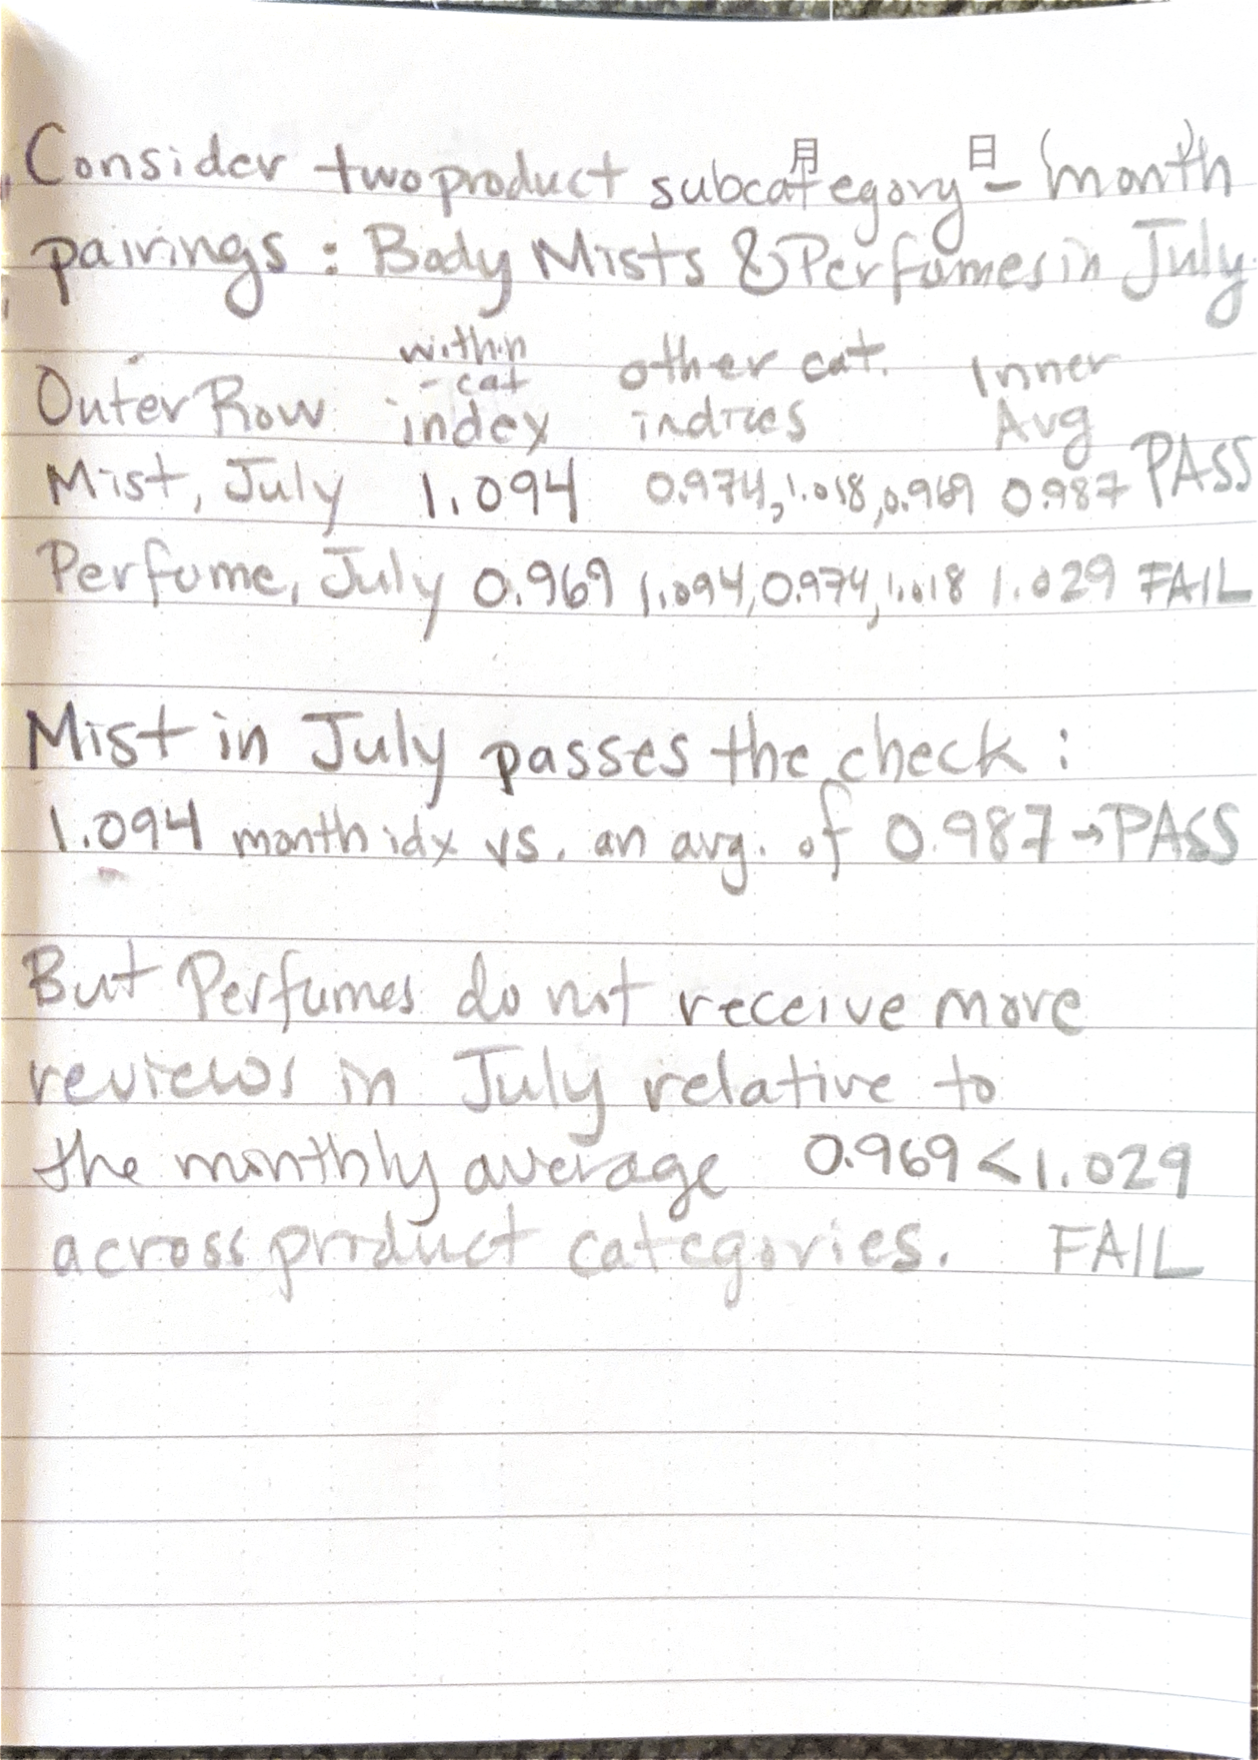

### Correlated Subquery 2: *Which scented-product subcategories receive more attention from reviewers in a given year, compared to the within-subcategory historical average?*

In [39]:
# measure each subcategory's share of all scented-product reviews in each year

con.sql("""
WITH yearly_group_counts AS (
    SELECT
        product_group,
        review_year,
        COUNT(*) AS group_reviews
    FROM all_scented_reviews
    GROUP BY product_group, review_year
),
yearly_totals AS (
    SELECT
        review_year,
        SUM(group_reviews) AS total_reviews
    FROM yearly_group_counts
    GROUP BY review_year
),
yearly_group_shares AS (
    --  each subcategory's yearly count as a pct. of that year's total
    SELECT
        g.product_group,
        g.review_year,
        100.0 * g.group_reviews / y.total_reviews
            AS yearly_share_pct
    FROM yearly_group_counts AS g
    JOIN yearly_totals AS y
        ON g.review_year = y.review_year
)
SELECT
    current_year.product_group,
    current_year.review_year,
    ROUND(current_year.yearly_share_pct, 2)
        AS yearly_share_pct,
    ROUND((
        SELECT AVG(historical.yearly_share_pct)
        FROM yearly_group_shares AS historical
        WHERE historical.product_group =
              current_year.product_group
    ), 2) AS historical_avg_pct
FROM yearly_group_shares AS current_year
-- match history to current subcategory
WHERE current_year.yearly_share_pct > (
    SELECT AVG(historical.yearly_share_pct)
    FROM yearly_group_shares AS historical
    WHERE historical.product_group =
          current_year.product_group
)
ORDER BY
    current_year.product_group,
    current_year.review_year
""").show(max_rows=25)

┌────────────────────────┬─────────────┬──────────────────┬────────────────────┐
│     product_group      │ review_year │ yearly_share_pct │ historical_avg_pct │
│        varchar         │    int64    │      double      │       double       │
├────────────────────────┼─────────────┼──────────────────┼────────────────────┤
│ Mist                   │        2019 │             7.22 │               6.43 │
│ Mist                   │        2020 │              7.4 │               6.43 │
│ Mist                   │        2021 │             8.58 │               6.43 │
│ Mist                   │        2022 │             8.64 │               6.43 │
│ Oil                    │        2016 │            15.09 │              14.87 │
│ Oil                    │        2017 │            21.02 │              14.87 │
│ Oil                    │        2018 │            19.18 │              14.87 │
│ Oil                    │        2020 │            21.49 │              14.87 │
│ Oil                    │  

Comment:

*The above query compares each product subcategory's yearly proportion of scented-product reviews against its historical avg from 2013–2022. Perfume review volume as a proportion of the total was above average from 2013–2016, while Body Mists and Sprays and Other Scented Products received relatively more attention from reviewers in later years.*

*These data suggest that reviewers (consumers?) have diversified the types of scented products they review. Relative proportions approximate product subcategory trends, although the general trend across years 2013-2022, when Amazon was expanding aggressively, is that reviews (sales?) increased in each product subcategory.*

## CTEs

### CTE 1: *Review Volume Seasonality, as a ratio to the average across months*

In [40]:
con.sql("""
WITH monthly_counts AS (
    SELECT
        review_year,
        review_month,
        COUNT(*) AS monthly_reviews
    FROM all_scented_reviews
    GROUP BY review_year, review_month
),
yearly_counts AS (
    SELECT
        review_year,
        SUM(monthly_reviews) AS yearly_reviews
    FROM monthly_counts
    GROUP BY review_year
),
monthly_activity AS (
    SELECT
        m.review_year,
        m.review_month,
        m.monthly_reviews,
        a.yearly_reviews,
        DAY(
            LAST_DAY(
                MAKE_DATE(m.review_year, m.review_month, 1)
            )
        ) AS days_in_month,
        CASE
            WHEN m.review_year % 400 = 0
              OR (
                  m.review_year % 4 = 0
                  AND m.review_year % 100 <> 0
              )
            THEN 366
            ELSE 365
        END AS days_in_year
    FROM monthly_counts AS m
    JOIN yearly_counts AS a
        ON m.review_year = a.review_year
)
-- avg each month's share of yearly reviews, 2013–2022
SELECT
    review_month,
    ROUND(
        AVG(
            (monthly_reviews * 1.0 / yearly_reviews)
            /
            (days_in_month * 1.0 / days_in_year)
        ),
        3
    ) AS daily_activity_index
FROM monthly_activity
GROUP BY review_month
ORDER BY daily_activity_index DESC
""").show()

┌──────────────┬──────────────────────┐
│ review_month │ daily_activity_index │
│    int64     │        double        │
├──────────────┼──────────────────────┤
│           12 │                1.277 │
│            1 │                1.225 │
│            2 │                1.056 │
│            3 │                1.002 │
│            7 │                0.985 │
│            8 │                0.983 │
│            6 │                0.931 │
│           11 │                0.918 │
│           10 │                0.918 │
│            9 │                0.909 │
│            5 │                0.895 │
│            4 │                0.893 │
├──────────────┴──────────────────────┤
│ 12 rows                   2 columns │
└─────────────────────────────────────┘



Comment:

 *We see increased reviews during calendar months December and January extending through March, and lesser increases in review volume during July and August. These data tentatively suggest that discretionary holiday shopping on scented products Nov-Mar drives review volume. April and May are then the "slump" months with the fewest fragrance reviews.*

*The CTEs count reviews by year and month, then calculate each month's proportion of yearly reviews.*

In [41]:
# sanity check comparing the two joined datasets

con.sql("""
WITH monthly_counts AS (
    SELECT
        source_collection,
        review_year,
        review_month,
        COUNT(*) AS monthly_reviews
    FROM all_scented_reviews
    GROUP BY
        source_collection,
        review_year,
        review_month
),
yearly_counts AS (
    SELECT
        source_collection,
        review_year,
        SUM(monthly_reviews) AS yearly_reviews
    FROM monthly_counts
    GROUP BY source_collection, review_year
),
monthly_activity AS (
    SELECT
        m.source_collection,
        m.review_year,
        m.review_month,
        m.monthly_reviews,
        a.yearly_reviews,
        DAY(
            LAST_DAY(
                MAKE_DATE(m.review_year, m.review_month, 1)
            )
        ) AS days_in_month,
        CASE
            WHEN m.review_year % 400 = 0
              OR (
                  m.review_year % 4 = 0
                  AND m.review_year % 100 <> 0
              )
            THEN 366
            ELSE 365
        END AS days_in_year
    FROM monthly_counts AS m
    JOIN yearly_counts AS a
        ON m.source_collection = a.source_collection
       AND m.review_year = a.review_year
)
SELECT
    source_collection,
    review_month,
    ROUND(
        AVG(
            (monthly_reviews * 1.0 / yearly_reviews)
            /
            (days_in_month * 1.0 / days_in_year)
        ),
        3
    ) AS daily_activity_index
FROM monthly_activity
GROUP BY source_collection, review_month
ORDER BY source_collection, review_month
""").show(max_rows=30)


┌────────────────────────┬──────────────┬──────────────────────┐
│   source_collection    │ review_month │ daily_activity_index │
│        varchar         │    int64     │        double        │
├────────────────────────┼──────────────┼──────────────────────┤
│ All Beauty             │            1 │                1.076 │
│ All Beauty             │            2 │                0.979 │
│ All Beauty             │            3 │                1.021 │
│ All Beauty             │            4 │                0.944 │
│ All Beauty             │            5 │                0.915 │
│ All Beauty             │            6 │                0.964 │
│ All Beauty             │            7 │                0.982 │
│ All Beauty             │            8 │                 1.04 │
│ All Beauty             │            9 │                0.925 │
│ All Beauty             │           10 │                 0.99 │
│ All Beauty             │           11 │                0.942 │
│ All Beauty             

Comment:

*At 10x the products and review, the Beauty & Personal Care dataset actually shows a stronger seasonal pattern. But December and the surrounding months, and to a lesser degree July and August, are the hot periods regardless.*

### CTE 2: *Review Volume Seasonality, by Scented Product Subcategory*

In [42]:
con.sql("""
WITH monthly_counts AS (
    SELECT
        product_group,
        review_year,
        review_month,
        COUNT(*) AS monthly_reviews
    FROM all_scented_reviews
    GROUP BY product_group, review_year, review_month
),
yearly_counts AS (
    SELECT
        product_group,
        review_year,
        SUM(monthly_reviews) AS yearly_reviews
    FROM monthly_counts
    GROUP BY product_group, review_year
),
monthly_activity AS (
    -- norm monthly review prop by days in each month
    SELECT
        m.product_group,
        m.review_year,
        m.review_month,
        m.monthly_reviews,
        y.yearly_reviews,
        DAY(
            LAST_DAY(
                MAKE_DATE(m.review_year, m.review_month, 1)
            )
        ) AS days_in_month,
        CASE
            WHEN m.review_year % 400 = 0
              OR (
                  m.review_year % 4 = 0
                  AND m.review_year % 100 <> 0
              )
            THEN 366
            ELSE 365
        END AS days_in_year
    FROM monthly_counts AS m
    JOIN yearly_counts AS y
        ON m.review_year = y.review_year
       AND m.product_group = y.product_group
)
-- avg each month norm across 2013–2022
SELECT
    product_group,
    review_month,
    ROUND(
        AVG(
            (monthly_reviews * 1.0 / yearly_reviews)
            /
            (days_in_month * 1.0 / days_in_year)
        ),
        3
    ) AS daily_activity_index,
    COUNT(*) AS years_observed
FROM monthly_activity
GROUP BY product_group, review_month
ORDER BY product_group, review_month
""").show(max_rows=50)

┌────────────────────────┬──────────────┬──────────────────────┬────────────────┐
│     product_group      │ review_month │ daily_activity_index │ years_observed │
│        varchar         │    int64     │        double        │     int64      │
├────────────────────────┼──────────────┼──────────────────────┼────────────────┤
│ Mist                   │            1 │                1.074 │             10 │
│ Mist                   │            2 │                0.952 │             10 │
│ Mist                   │            3 │                0.949 │             10 │
│ Mist                   │            4 │                0.883 │             10 │
│ Mist                   │            5 │                0.931 │             10 │
│ Mist                   │            6 │                0.964 │             10 │
│ Mist                   │            7 │                1.094 │             10 │
│ Mist                   │            8 │                1.086 │             10 │
│ Mist          

Comment:

*For discussion, see the answer to Research Question 2 below.*

## Window Functions

### Window Function 1: *Review Seasonality, by scented product subcategory*

In [43]:
# rank months by normalized review freq for each subcategory
con.sql("""
WITH monthly_counts AS (
    SELECT
        product_group,
        review_year,
        review_month,
        COUNT(*) AS monthly_reviews
    FROM all_scented_reviews
    GROUP BY product_group, review_year, review_month
),
yearly_counts AS (
    SELECT
        product_group,
        review_year,
        SUM(monthly_reviews) AS yearly_reviews
    FROM monthly_counts
    GROUP BY product_group, review_year
),
monthly_activity AS (
    -- normalize monthly review prop by days in each month
    SELECT
        m.product_group,
        m.review_year,
        m.review_month,
        (m.monthly_reviews * 1.0 / y.yearly_reviews)
        /
        (
            DAY(LAST_DAY(
                MAKE_DATE(m.review_year, m.review_month, 1)
            )) * 1.0
            /
            CASE
                -- leap years
                WHEN m.review_year % 400 = 0
                  OR (m.review_year % 4 = 0
                      AND m.review_year % 100 <> 0)
                THEN 366
                ELSE 365
            END
        ) AS daily_activity_index
    FROM monthly_counts AS m
    JOIN yearly_counts AS y
        ON m.review_year = y.review_year
       AND m.product_group = y.product_group
),
group_month_indices AS (
    SELECT
        product_group,
        review_month,
        AVG(daily_activity_index) AS avg_index
    FROM monthly_activity
    GROUP BY product_group, review_month
)
SELECT
    product_group,
    review_month,
    ROUND(avg_index, 3) AS daily_activity_index,
    -- rank months within each product subcategory
    RANK() OVER (
        PARTITION BY product_group
        ORDER BY avg_index DESC
    ) AS month_rank
FROM group_month_indices
ORDER BY product_group, month_rank
""").show(max_rows=50)


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

┌────────────────────────┬──────────────┬──────────────────────┬────────────┐
│     product_group      │ review_month │ daily_activity_index │ month_rank │
│        varchar         │    int64     │        double        │   int64    │
├────────────────────────┼──────────────┼──────────────────────┼────────────┤
│ Mist                   │           12 │                 1.25 │          1 │
│ Mist                   │            7 │                1.094 │          2 │
│ Mist                   │            8 │                1.086 │          3 │
│ Mist                   │            1 │                1.074 │          4 │
│ Mist                   │            9 │                0.973 │          5 │
│ Mist                   │            6 │                0.964 │          6 │
│ Mist                   │            2 │                0.952 │          7 │
│ Mist                   │            3 │                0.949 │          8 │
│ Mist                   │            5 │                0.931 │

Comment:

*December ranks first for all four subcategories. July and August rank second and third for Body Mists and Sprays.*

### Window Function 2: RANK vs ROW_NUMBER comparison, using top fragrance mist and body spray products

In [44]:
con.sql("""
WITH product_counts AS (
    SELECT
        product_group,
        parent_asin,
        COUNT(*) AS review_count
    FROM all_scented_reviews
    WHERE product_group = 'Mist'
    GROUP BY product_group, parent_asin
),
-- three products selected to demonstrate a tie
debug_products AS (
    SELECT
        product_group,
        parent_asin,
        review_count
    FROM product_counts
    WHERE parent_asin IN (
        'B001KNTPUC',
        'B002VWK8HU'
    )

    UNION ALL

    (
        SELECT
            product_group,
            parent_asin,
            review_count
        FROM product_counts
        WHERE review_count = 14
        ORDER BY parent_asin
        LIMIT 1
    )
)
SELECT
    parent_asin,
    review_count,
    -- tied review counts receive the same rank
    RANK() OVER (
        ORDER BY review_count DESC
    ) AS product_rank,
    ROW_NUMBER() OVER (
        -- break ties using parent_asin to assign unique row numbers
        ORDER BY review_count DESC, parent_asin
    ) AS row_num
FROM debug_products
ORDER BY row_num
""").show()

┌─────────────┬──────────────┬──────────────┬─────────┐
│ parent_asin │ review_count │ product_rank │ row_num │
│   varchar   │    int64     │    int64     │  int64  │
├─────────────┼──────────────┼──────────────┼─────────┤
│ B001KNTPUC  │           15 │            1 │       1 │
│ B002VWK8HU  │           15 │            1 │       2 │
│ B002Z7FUYW  │           14 │            3 │       3 │
└─────────────┴──────────────┴──────────────┴─────────┘



**Debug table (required, 8 pts)**: paste a photo of your hand-traced window function here. Make the partition and order visible. If you chose RANK, show ties producing 1,1,3. If ROW_NUMBER, show 1,2,3.

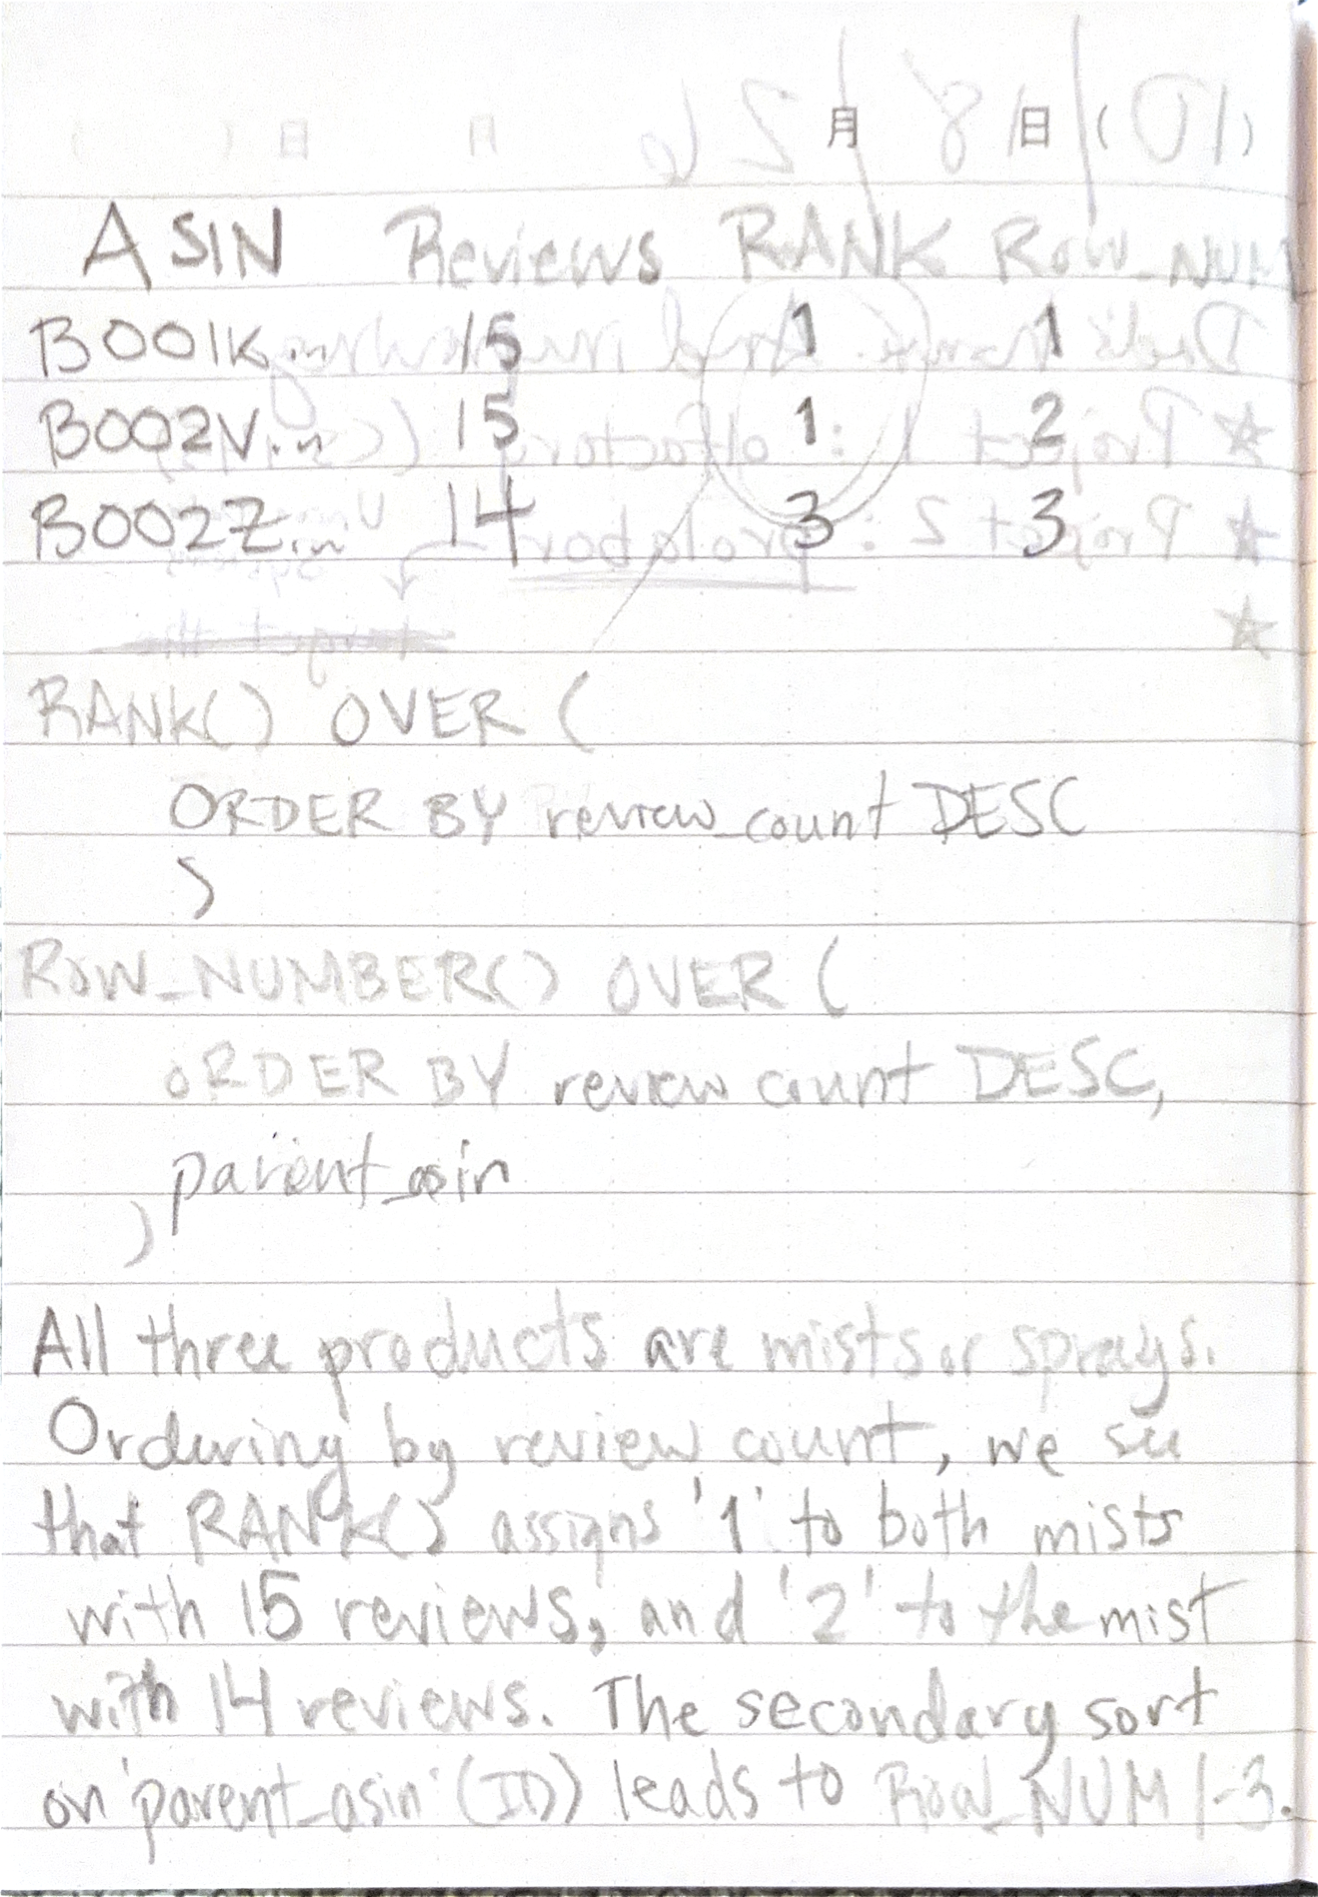

### Window Function 3: *Within-Subcategory Variance by Month*

In [45]:
con.sql("""
WITH monthly_counts AS (
    SELECT
        product_group,
        review_year,
        review_month,
        COUNT(*) AS monthly_reviews
    FROM all_scented_reviews
    GROUP BY product_group, review_year, review_month
),
yearly_counts AS (
    SELECT
        product_group,
        review_year,
        SUM(monthly_reviews) AS yearly_reviews
    FROM monthly_counts
    GROUP BY product_group, review_year
),
-- normalize monthly review prop for length in days
monthly_activity AS (
    SELECT
        m.product_group,
        m.review_year,
        m.review_month,
        (m.monthly_reviews * 1.0 / y.yearly_reviews)
        /
        (
            DAY(LAST_DAY(
                MAKE_DATE(m.review_year, m.review_month, 1)
            )) * 1.0
            /
            CASE
                WHEN m.review_year % 400 = 0
                  OR (m.review_year % 4 = 0
                      AND m.review_year % 100 <> 0)
                THEN 366
                ELSE 365
            END
        ) AS daily_activity_index
    FROM monthly_counts AS m
    JOIN yearly_counts AS y
        ON m.product_group = y.product_group
       AND m.review_year = y.review_year
),
-- avg each month's norm across 2013–2022
group_month_indices AS (
    SELECT
        product_group,
        review_month,
        AVG(daily_activity_index) AS activity_index
    FROM monthly_activity
    GROUP BY product_group, review_month
),
-- mean + standard dev across months within each subcategory
group_consistency AS (
    SELECT
        product_group,
        review_month,
        activity_index,
        AVG(activity_index) OVER (
            PARTITION BY product_group
        ) AS avg_activity_index,
        STDDEV_POP(activity_index) OVER (
            PARTITION BY product_group
        ) AS seasonal_stddev
    FROM group_month_indices
)
-- compare product subcategories by coeff of variation
SELECT
    product_group,
    ROUND(MAX(seasonal_stddev), 3)
        AS seasonal_variation,
    ROUND(
        MAX(seasonal_stddev)
        / NULLIF(MAX(avg_activity_index), 0),
        3
    ) AS coefficient_of_variation
FROM group_consistency
GROUP BY product_group
ORDER BY coefficient_of_variation ASC
""").show()

┌────────────────────────┬────────────────────┬──────────────────────────┐
│     product_group      │ seasonal_variation │ coefficient_of_variation │
│        varchar         │       double       │          double          │
├────────────────────────┼────────────────────┼──────────────────────────┤
│ Other Scented Products │              0.079 │                    0.079 │
│ Mist                   │              0.102 │                    0.102 │
│ Oil                    │               0.11 │                    0.111 │
│ Perfume                │              0.148 │                    0.148 │
└────────────────────────┴────────────────────┴──────────────────────────┘



Comment:

*Among the four scented-product subcategories, the catchall "other" category had the most consistent review activity during 2013–2022, with a coefficient of variation of 0.079 across months. Perfume review volume varied significantly more by season (CoV 0.148).*

*This pattern would be explained by seasonal perfume marketing campaigns already being a thing. It might also suggest the efficacy of continuing / introducing seasonal perfume marketing campaigns in the future. In any event, pronounced seasonality appears to be a feature of perfume reviews (and sales?) in particular.*

<a name="section-4"></a>

# Section 4: Exploring Central Questions

## Question 1: *Which months show higher scented-product review activity, controlling for yearly review volume and length of month?*

In [46]:
rq1 = con.sql("""
WITH scented_reviews AS (
    -- join reviews to filtered scented products table and combine
    SELECT
        YEAR(epoch_ms(r.timestamp)) AS review_year,
        MONTH(epoch_ms(r.timestamp)) AS review_month
    FROM all_beauty_reviews AS r
    JOIN all_beauty_scented_filtered AS p
        ON r.parent_asin = p.parent_asin
    WHERE p.product_group IS NOT NULL
      AND YEAR(epoch_ms(r.timestamp)) BETWEEN 2013 AND 2022

    UNION ALL

    SELECT
        YEAR(epoch_ms(r.timestamp)) AS review_year,
        MONTH(epoch_ms(r.timestamp)) AS review_month
    FROM bpc_scented_reviews AS r
    JOIN bpc_scented_products_filtered AS p
        ON r.parent_asin = p.parent_asin
    WHERE YEAR(epoch_ms(r.timestamp)) BETWEEN 2013 AND 2022
),
monthly_counts AS (
    SELECT
        review_year,
        review_month,
        COUNT(*) AS monthly_reviews
    FROM scented_reviews
    GROUP BY review_year, review_month
),
yearly_counts AS (
    SELECT
        review_year,
        SUM(monthly_reviews) AS yearly_reviews
    FROM monthly_counts
    GROUP BY review_year
),
monthly_activity AS (
    -- month, year lengths, and leap years
    SELECT
        m.review_year,
        m.review_month,
        m.monthly_reviews,
        y.yearly_reviews,
        DAY(
            LAST_DAY(
                MAKE_DATE(m.review_year, m.review_month, 1)
            )
        ) AS days_in_month,
        CASE
            WHEN m.review_year % 400 = 0
              OR (
                  m.review_year % 4 = 0
                  AND m.review_year % 100 <> 0
              )
            THEN 366
            ELSE 365
        END AS days_in_year
    FROM monthly_counts AS m
    JOIN yearly_counts AS y
        ON m.review_year = y.review_year
)
-- avg each month's yearly prop across years, accounting for lenghts in days
SELECT
    review_month,
    ROUND(
        AVG(
            100.0 * monthly_reviews / yearly_reviews
        ),
        2
    ) AS avg_annual_share_pct,
    ROUND(
        AVG(
            (monthly_reviews * 1.0 / yearly_reviews)
            /
            (days_in_month * 1.0 / days_in_year)
        ),
        3
    ) AS daily_activity_index,
    COUNT(*) AS years_observed
FROM monthly_activity
GROUP BY review_month
ORDER BY daily_activity_index DESC
""").df()

In [47]:
rq1.head(12)

,review_month,avg_annual_share_pct,daily_activity_index,years_observed
0,12,10.84,1.277,10
1,1,10.40,1.225,10
2,2,8.16,1.056,10
3,3,8.51,1.002,10
4,7,8.36,0.985,10
5,8,8.34,0.983,10
6,6,7.65,0.931,10
7,11,7.54,0.918,10
8,10,7.80,0.918,10
9,9,7.47,0.909,10


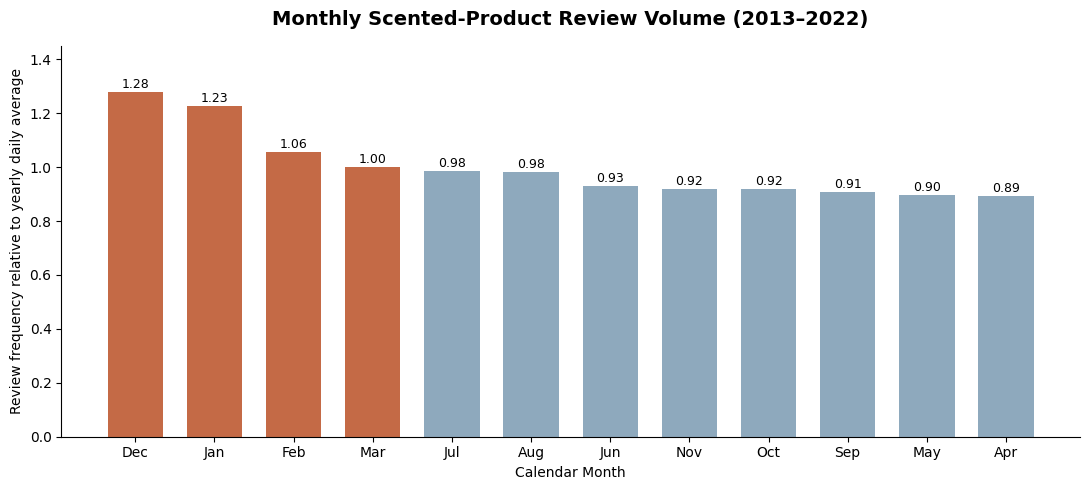

In [48]:
# adding bar chart to visualize data
import matplotlib.pyplot as plt
import calendar

months = [calendar.month_abbr[int(m)] for m in rq1["review_month"]]
indices = rq1["daily_activity_index"]

fig, ax = plt.subplots(figsize=(11, 5))

colors = [
    "#C46A46" if value > 1 else "#8EA9BD"
    for value in indices
]

bars = ax.bar(months, indices, color=colors, width=0.7)

for bar, value in zip(bars, indices):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.015,
        f"{value:.2f}",
        ha="center", fontsize=9
    )

ax.set_title(
    "Monthly Scented-Product Review Volume (2013–2022)",
    fontsize=14, fontweight="bold", pad=15
)
ax.set_ylabel("Review frequency relative to yearly daily average")
ax.set_xlabel("Calendar Month")
ax.set_ylim(0, 1.45)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

Comment:

*According to [Hu et al.'s (2024) Amazon data](https://amazon-reviews-2023.github.io/index.html), scented product reviewers leave more reviews during December and January, even when accounting for yearly volume and calendar-month length.*

*July and August see a slight increase in scented product review activity, at least relative to the "slump" months of April and May. Summer fluctuations in review frequency appear small compared to the holiday / Winter rush. (Although, the earlier query in Window Function 1 showed that Body Mists and Sprays garner more reviews, relative to their average across months, during the Summer.)*

*Presumably, stockists already plan during the Fall months for the Winter rush. The data provide tentative evidence that reviewers of scented beauty and personal care products are more active throughout the Winter. Such could be due to holidays, climate, or other factors. Reviews =/= sales.*

*1.0 = average daily review frequency for the year. Values > 1.0 indicate greater review frequency.*

## Question 2: *Which scented product subcategories gain relatively more attention during different months (Dec-Jan, for example)?*

In [49]:
con.sql("""
WITH scented_reviews AS (
    -- join reviews to filtered scented product and combine
    SELECT
        p.product_group,
        YEAR(epoch_ms(r.timestamp)) AS review_year,
        MONTH(epoch_ms(r.timestamp)) AS review_month
    FROM all_beauty_reviews AS r
    JOIN all_beauty_scented_filtered AS p
        ON r.parent_asin = p.parent_asin
    WHERE p.product_group IS NOT NULL
      AND YEAR(epoch_ms(r.timestamp))
          BETWEEN 2013 AND 2022

    UNION ALL

    SELECT
        p.product_group,
        YEAR(epoch_ms(r.timestamp)) AS review_year,
        MONTH(epoch_ms(r.timestamp)) AS review_month
    FROM bpc_scented_reviews AS r
    JOIN bpc_scented_products_filtered AS p
        ON r.parent_asin = p.parent_asin
    WHERE YEAR(epoch_ms(r.timestamp))
          BETWEEN 2013 AND 2022
),
monthly_counts AS (
    SELECT
        product_group,
        review_year,
        review_month,
        COUNT(*) AS monthly_reviews
    FROM scented_reviews
    GROUP BY product_group, review_year, review_month
),
yearly_counts AS (
    SELECT
        product_group,
        review_year,
        SUM(monthly_reviews) AS yearly_reviews
    FROM monthly_counts
    GROUP BY product_group, review_year
),
monthly_activity AS (
    -- month, year lengths, and leap years
    SELECT
        m.product_group,
        m.review_year,
        m.review_month,
        (m.monthly_reviews * 1.0 / y.yearly_reviews)
        /
        (
            DAY(LAST_DAY(
                MAKE_DATE(m.review_year, m.review_month, 1)
            )) * 1.0
            /
            CASE
                WHEN m.review_year % 400 = 0
                  OR (
                      m.review_year % 4 = 0
                      AND m.review_year % 100 <> 0
                  )
                THEN 366
                ELSE 365
            END
        ) AS daily_activity_index
    FROM monthly_counts AS m
    JOIN yearly_counts AS y
        ON m.product_group = y.product_group
       AND m.review_year = y.review_year
)
-- avg each month's yearly prop across years, accounting for lenghts in days
SELECT
    product_group,
    CASE
        WHEN review_month IN (12, 1)
            THEN 'Winter'
        ELSE 'Summer'
    END AS season,
    ROUND(AVG(daily_activity_index), 3)
        AS avg_daily_activity_index,
    COUNT(*) AS observations
FROM monthly_activity
WHERE review_month IN (12, 1, 7, 8)
GROUP BY product_group, season
ORDER BY season, avg_daily_activity_index DESC
""").show()

┌────────────────────────┬─────────┬──────────────────────────┬──────────────┐
│     product_group      │ season  │ avg_daily_activity_index │ observations │
│        varchar         │ varchar │          double          │    int64     │
├────────────────────────┼─────────┼──────────────────────────┼──────────────┤
│ Mist                   │ Summer  │                     1.09 │           20 │
│ Other Scented Products │ Summer  │                    1.005 │           20 │
│ Oil                    │ Summer  │                    0.988 │           20 │
│ Perfume                │ Summer  │                    0.967 │           20 │
│ Perfume                │ Winter  │                    1.301 │           20 │
│ Oil                    │ Winter  │                    1.191 │           20 │
│ Mist                   │ Winter  │                    1.162 │           20 │
│ Other Scented Products │ Winter  │                    1.149 │           20 │
└────────────────────────┴─────────┴────────────────

Comments:

*Comparing review frequency during Winter (December + January) and Summer (July + August) shows that perfumes receive roughly 30% more reviews during mid-Winter, and about 3% less reviews at the height of Summer (again, norming on North America). Body Mists and Sprays as a subcategory receive approx. 9% more reviews during Summer, although they get even more reviews during Winter, too (16%-ish).*

*These data suggest, somewhat obviously, that different scented-product subcategories might be promoted on different yearly schedules. Perfumes and oils for the Winter, Body Mists and Sprays for the Summer.*

## Question 3: *Does the proportion of scented-product reviews marked as "verified purchases" vary by season and / or by product subcategory?*

In [50]:

# Compare verified-purchase review rates across seasons and product subcategories

con.sql("""
WITH seasonal_reviews AS (
    SELECT
        p.product_group,
        YEAR(epoch_ms(r.timestamp)) AS review_year,
        r.verified_purchase,
        CASE
            WHEN MONTH(epoch_ms(r.timestamp)) IN (12, 1)
                THEN 'Winter'
            WHEN MONTH(epoch_ms(r.timestamp)) IN (7, 8)
                THEN 'Summer'
            ELSE 'Other Months'
        END AS season
    FROM all_beauty_reviews AS r
    JOIN all_beauty_scented_filtered AS p
        ON r.parent_asin = p.parent_asin
    WHERE p.product_group IS NOT NULL
      AND YEAR(epoch_ms(r.timestamp)) BETWEEN 2013 AND 2022

    UNION ALL

    SELECT
        p.product_group,
        YEAR(epoch_ms(r.timestamp)) AS review_year,
        r.verified_purchase,
        CASE
            WHEN MONTH(epoch_ms(r.timestamp)) IN (12, 1)
                THEN 'Winter'
            WHEN MONTH(epoch_ms(r.timestamp)) IN (7, 8)
                THEN 'Summer'
            ELSE 'Other Months'
        END AS season
    FROM bpc_scented_reviews AS r
    JOIN bpc_scented_products_filtered AS p
        ON r.parent_asin = p.parent_asin
    WHERE YEAR(epoch_ms(r.timestamp)) BETWEEN 2013 AND 2022
),
yearly_rates AS (
    -- Calculate verified-purchase percentages separately for each year
    SELECT
        product_group,
        review_year,
        season,
        COUNT(*) FILTER (WHERE verified_purchase = TRUE)
            AS verified_reviews,
        COUNT(verified_purchase) AS reviews_with_status
    FROM seasonal_reviews
    GROUP BY product_group, review_year, season
)
SELECT
    product_group,
    season,
    ROUND(
        AVG(100.0 * verified_reviews
            / NULLIF(reviews_with_status, 0)),
        2
    ) AS verified_review_pct
FROM yearly_rates
GROUP BY product_group, season
ORDER BY product_group, season
""").show()

┌────────────────────────┬──────────────┬─────────────────────┐
│     product_group      │    season    │ verified_review_pct │
│        varchar         │   varchar    │       double        │
├────────────────────────┼──────────────┼─────────────────────┤
│ Mist                   │ Other Months │               92.26 │
│ Mist                   │ Summer       │               90.53 │
│ Mist                   │ Winter       │               93.03 │
│ Oil                    │ Other Months │               87.03 │
│ Oil                    │ Summer       │               86.83 │
│ Oil                    │ Winter       │               88.98 │
│ Other Scented Products │ Other Months │               88.28 │
│ Other Scented Products │ Summer       │               88.53 │
│ Other Scented Products │ Winter       │               90.84 │
│ Perfume                │ Other Months │               93.63 │
│ Perfume                │ Summer       │               93.17 │
│ Perfume                │ Winter       

Comment:

*The pct. of reviews of "verified purchases" is higher during the peak Winter months (December + January) than during peak Summer months (July + August) for all four scented-product subcategories. The seasonal difference in "verified purchaser" reviews is largest for Body Mists and Sprays (93.03% vs. 90.53%), and smallest for Perfume (93.93% vs. 93.17%). These are small differences, although I would have expected fewer reviews of verified purchases during the busier season. The fact that user reviews of Body Mists and Sprays are less likely to be associated with "verified purchases" during the Summer months, when they are more popular with reviewers, is a bit odd. I suspect that frequent Amazon shoppers / reviewers, who are perhaps more active during Winter, are driving the trend."*



<a name="section-5"></a>

# Section 5: AI Takeaways

## AI Anecdotes (6 pts)

**Anecdote 1** — *Mixed data in cols were read from JSON. DuckDB failed to import Beauty & Personal Care metadata at first, because the price col contained strings like "from 28.00". Using AI to draft an unfamiliar json import function call led me straight to an error. Setting price as VARCHAR solved the error.*


**Anecdote 2** — *The product categorization heuristics were wrong. AI was too hasty in slapping together product subcategories based on regexes, as was I. Title regexes captured listings for empty "perfume" bottles, "essential oil" diffusers, and "unscented" products. I filtered out some obviously wrong products, like those with "unscented" in the title. But moving quickly with AI, I only implemented a partial filter to exclude some categories. It would have been better to use AI to draft and run a fuller set of heuristic checks against Amazon's extant product categorizations.*


**Anecdote 3** — *AI repeatedly referred to the norm of the index I constructed, which is 1.0 or very close to 1.0 by design, as though it needed emphasis. Model generations suggested reporting the "average activity index," which is neither useful nor informative, except in explaining the idea behind the index (review volume for a given month, relative to review volume averaged over months, first averaged over years). It seems to me that AI may "fixate" on a metric, any metric, as though it is important, even when we've just made it up. Call it Goodheart's law of AI, or something like that.*


## Explain One Query in Plain English (4 pts)

In [51]:

# Compare each subcategory's monthly review activity against the other three

con.sql("""
WITH monthly_counts AS (
    SELECT
        product_group,
        review_year,
        review_month,
        COUNT(*) AS monthly_reviews
    FROM all_scented_reviews
    GROUP BY product_group, review_year, review_month
),
yearly_counts AS (
    SELECT
        product_group,
        review_year,
        SUM(monthly_reviews) AS yearly_reviews
    FROM monthly_counts
    GROUP BY product_group, review_year
),
monthly_activity AS (
    -- norm monthly review count by yearly volume and month length in days
    SELECT
        m.product_group,
        m.review_year,
        m.review_month,
        (m.monthly_reviews * 1.0 / y.yearly_reviews)
        /
        (
            DAY(LAST_DAY(
                MAKE_DATE(m.review_year, m.review_month, 1)
            )) * 1.0
            /
            CASE
                WHEN m.review_year % 400 = 0
                  OR (
                      m.review_year % 4 = 0
                      AND m.review_year % 100 <> 0
                  )
                THEN 366
                ELSE 365
            END
        ) AS daily_activity_index
    FROM monthly_counts AS m
    JOIN yearly_counts AS y
        ON m.product_group = y.product_group
       AND m.review_year = y.review_year
),
group_month_indices AS (
    SELECT
        product_group,
        review_month,
        AVG(daily_activity_index) AS activity_index
    FROM monthly_activity
    GROUP BY product_group, review_month
)
SELECT
    current_group.product_group,
    current_group.review_month,
    ROUND(current_group.activity_index, 3)
        AS activity_index,
    ROUND((
        -- avg for other three subcategories in the same month
        SELECT AVG(other_group.activity_index)
        FROM group_month_indices AS other_group
        WHERE other_group.review_month =
              current_group.review_month
          AND other_group.product_group <>
              current_group.product_group
    ), 3) AS other_groups_avg
FROM group_month_indices AS current_group
WHERE current_group.activity_index > (
    -- keep only subcategory > other subcategories' monthly avg
    SELECT AVG(other_group.activity_index)
    FROM group_month_indices AS other_group
    WHERE other_group.review_month =
          current_group.review_month
      AND other_group.product_group <>
          current_group.product_group
)
ORDER BY
    current_group.review_month,
    current_group.activity_index DESC
""").show(max_rows=30)

┌────────────────────────┬──────────────┬────────────────┬──────────────────┐
│     product_group      │ review_month │ activity_index │ other_groups_avg │
│        varchar         │    int64     │     double     │      double      │
├────────────────────────┼──────────────┼────────────────┼──────────────────┤
│ Perfume                │            1 │            1.3 │            1.072 │
│ Perfume                │            2 │           1.09 │            0.969 │
│ Other Scented Products │            2 │          1.028 │             0.99 │
│ Perfume                │            3 │          1.005 │            0.979 │
│ Oil                    │            3 │          1.002 │             0.98 │
│ Other Scented Products │            3 │          0.986 │            0.985 │
│ Other Scented Products │            4 │          0.945 │            0.895 │
│ Oil                    │            4 │           0.94 │            0.897 │
│ Other Scented Products │            5 │          0.953 │      

**Correlated Subquery 1 (pasted above)**

*The CTEs count reviews for each subcategory by year and month. They calculate what percentage of each year's reviews were posted during each month, adjust for the number of days per month, and average the results over a ten-year period (2013–2022).*

*The outer query selects each subcategory and month. The inner (correlated) query calculates the avg activity of the other three subcategories during that same month, using the outer row to match the month and exclude the current subcategory.*

*The outer query then filters for cases where a subcategory's normalized monthly review activity exceeds the average of its counterparts' activity during that same calendar month. For instance, Body Mists and Sprays stand out during July and August.*


## Notebook Hygiene Checklist (10 pts)

Before you submit:
* [ ] Table of Contents is visible at the top.
* [ ] Every cell has been run and every output is visible.
* [ ] Every query has a comment **in your own words** (not raw AI responses pasted in).
* [ ] Consistent naming and formatting, so the notebook reads like a finished deliverable.
* [ ] Submission is a single `.ipynb` uploaded to Gradescope.


<a name="section-6"></a>

# Section 6: Wrap-Up

*Scented beauty and personal care product reviews are posted on Amazon most frequently during the dead of winter and, to a much lesser extent, the height of summer (relative to North America). Four product categories were identified, based on listing titles: (1) perfumes and colognes, (2) body sprays and mists, (3) fragrance and essential oils, (4) and a catchall "other" scented beauty product subcategory.*

*Each subcategory shows a seasonal trend. Perfumes and oils receive more reviews overall, but especially during December and January. Body sprays and mists get the same holiday boost, but receive relatively more reviewer attention during July and August. Because perfumes are the focus of a majority of scented beauty product reviews filtered from the dataset, and because perfumes are seasonally "swingy" in terms of Amazon review volume, it may be sensible to focus on seasonal promotion opportunities specifically in the perfume and cologne market segment. Among the subcategories of scented products identified in this analysis, perfume reviews may also be more likely to be associated with a verified Amazon purchase. It therefore seems that parfums and eaux de toilette require a great deal of marketing strategy.*

*Tl;dr Stockists should perhaps consider prioritizing Fall inventory updates of Perfumes and Essential Oils, and late Spring product orders of Body Mists and Sprays.*

*If I were to repeat the project, I would spend more time on the product subcategorizations. The regex-based "perfume" and "mist" filters are approximate, and the catchall `Other Scented Products` group is uninterpretable as it stands. Better category definitions, using Amazon's extant scheme, preferably coupled with data on actual purchases, would improve the project.*
